# λ-PCG


In [8]:
# 如缺少依赖，可取消注释运行：
# %pip install numpy matplotlib


In [9]:
import numpy as np
from numpy import zeros


## 1. 原有正演矩阵与真实模型

In [10]:
def system_matrix(s, N, h, x, M, l_y, l_z):
    A = zeros((M + 1, N + 1))
    G = -6.67e-11
    for i in range(M + 1):
        A[i, 0] = -0.5 * G * h / ((x[i] - s[0]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
        for j in range(1, N):
            A[i, j] = -G * h / ((x[i] - s[j]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
        A[i, N] = -0.5 * G * h / ((x[i] - s[N]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
    return A
def rho_model(s):
    return (2 * np.exp(-(s - 0.382)**2 / 0.009)
            + 1.2 * np.exp(-(s - 0.618)**2 / 0.018))


## 2. 精简的交叉近似和预条件器

`epsilon` 控制交叉近似，`tau=0.1*lambda` 控制再压缩；这两个阈值不同。


In [11]:
class IdentityPreconditioner:
    def apply(self, u):
        return u.copy()


class RegNormalPreconditioner:
    def __init__(self, V, sigma, lam):
        if lam <= 0:
            raise ValueError("lambda 必须大于 0")
        self.V = V
        self.sigma = sigma
        self.lambda2 = lam**2
        self.rank = len(sigma)

    def apply(self, u):
        c = self.V.T @ u
        return (self.V @ (c / (self.sigma**2 + self.lambda2))+ (u - self.V @ c) / self.lambda2)


def cross_approximation(A, epsilon=1e-8):
    M, N = A.shape
    B = np.empty((M, 0))
    C = np.empty((N, 0))
    I, J = list(range(M)), list(range(N))
    R = 0
    rng = np.random.default_rng(0)
    while I and J:
        j = int(rng.choice(J))
        for _ in range(2):
            col = A[:, j] - B @ C[j, :]
            i = I[int(np.argmax(np.abs(col[I])))]
            row = A[i, :] - C @ B[i, :]
            j = J[int(np.argmax(np.abs(row[J])))]
        pivot = A[i, j] - B[i, :] @ C[j, :]
        if pivot == 0:
            break
        norm_BC = np.sqrt(np.sum((B.T @ B) * (C.T @ C)))
        estimate = abs(pivot) * np.sqrt((M - R - 1) * (N - R - 1))
        if estimate <= epsilon * norm_BC:
            break
        b_col = (A[:, j] - B @ C[j, :])
        c_col = (A[i, :] - C @ B[i, :]) / pivot
        R = R + 1
        B = np.column_stack((B, b_col))
        C = np.column_stack((C, c_col))

        I.remove(i)
        J.remove(j)

    return B, C


def recompress_factors(B, C, tau):
    if B.shape[1] == 0:
        return np.empty((B.shape[0], 0)), np.empty(0), np.empty((C.shape[0], 0))
    Q_B, T_B = np.linalg.qr(B)
    Q_C, T_C = np.linalg.qr(C)
    U_hat, sigma, V_hat_T = np.linalg.svd(T_B @ T_C.T, full_matrices=False)
    keep = sigma > tau
    U = Q_B @ U_hat[:, keep]
    V = Q_C @ V_hat_T[keep, :].T
    return U, sigma[keep], V


def build_preconditioner(A, lam, cutoff_ratio=0.1, epsilon=1e-8):
    B, C = cross_approximation(A, epsilon)
    tau = cutoff_ratio * lam
    U, sigma, V = recompress_factors(B, C, tau)
    prec = RegNormalPreconditioner(V, sigma, lam)
    return prec, {'rank': prec.rank, 'cross_rank': B.shape[1], 'tau': tau}



## 3. 算法 2：

初始化 $r=b-Ax$，$u=A^Tr-\lambda^2x$，$z=L^{-1}u$，$p=z$。循环计算步长、更新 x 和 r，再计算 u_new、z_new、beta 和新方向 p。


In [12]:
def rCGNR(A, preconditioner, b, x0, lambda2, delta_true):
    x = np.array(x0, dtype=float, copy=True)
    r = b - A @ x
    u = A.T @ r - lambda2 * x
    # if np.linalg.norm(A @ x - b)**2 < delta_true**2:
    #     return x, 0, True


    z = preconditioner.apply(u)
    p = z.copy()

    for k in range(200):
        Ap = A @ p
        uz = u @ z
        denominator = Ap @ Ap + lambda2 * (p @ p)
        step = uz / denominator
        x = x + step * p
        r = r - step * Ap
        u_new = A.T @ r - lambda2 * x
        if np.linalg.norm(A @ x - b)**2 < delta_true**2:
            return x, k+1, True
        z_new = preconditioner.apply(u_new)
        beta = (u_new @ z_new) / uz
        p = z_new + beta * p
        u, z = u_new, z_new
    return x,k+1, False

## 4. 生成模型、含噪观测与反演网格

In [13]:
a, b = 0.0, 1.0
N_model = 100
s_model = np.linspace(a, b, N_model + 1)
X_model = rho_model(s_model)
M = 200
x_grid = np.linspace(-1.0, 2.0, M + 1)
l_y, l_z = 0.2, 0.1
A_model = system_matrix(s_model, N_model, (b-a)/N_model,
                        x_grid, M, l_y, l_z)
B = A_model @ X_model
delta = 0.001
rng = np.random.RandomState(1)
B_delta = B + delta * B * (rng.random_sample(len(B))- rng.random_sample(len(B)))
delta_true = np.linalg.norm(B_delta - B)

N = 50
s = np.linspace(a, b, N + 1)
A = system_matrix(s, N, (b-a)/N, x_grid, M, l_y, l_z)
x_init = np.zeros(N + 1)
alpha = 4e-27
lam = np.sqrt(alpha)
cutoff_ratio = 0.1


## 5. 运行

In [14]:
preconditioner, prec_info = build_preconditioner(A, lam, cutoff_ratio)
X_inv, iterations, converged = rCGNR(A, preconditioner, B_delta, x_init, alpha, delta_true)
X_cgnr, iterations_cgnr, converged_cgnr = rCGNR(A, IdentityPreconditioner(), B_delta, x_init, alpha, delta_true)
X_tikhonov = np.linalg.solve(A.T @ A + alpha * np.eye(N + 1), A.T @ B_delta)
print(f"预条件器保留秩：{prec_info['rank']}")
print(f"PCGNR：{iterations} 次迭代，满足停止条件：{converged}")
print(f"CGNR：{iterations_cgnr} 次迭代，满足停止条件：{converged_cgnr}")
print(f"实际噪声范数平方：{delta_true**2:.6e}")


预条件器保留秩：16
PCGNR：1 次迭代，满足停止条件：True
CGNR：14 次迭代，满足停止条件：True
实际噪声范数平方：2.198596e-25


## 6. 绘图

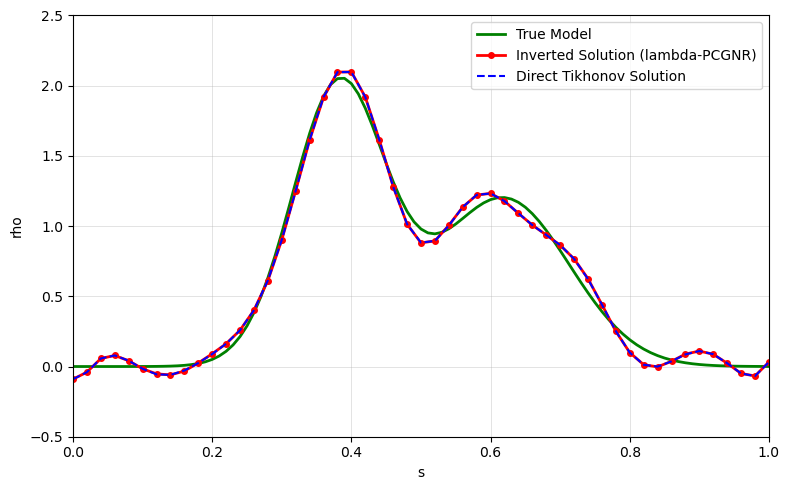

In [15]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 5))
ax = plt.axes(xlim=(a, b), ylim=(-0.5, 2.5))
ax.set_xlabel("s")
ax.set_ylabel("rho")
ax.plot(s_model, X_model, "-g", lw=2, label="True Model")
ax.plot(s, X_inv, "-or", lw=2, markersize=4,
        label="Inverted Solution (lambda-PCGNR)")
ax.plot(s, X_tikhonov, "--b", lw=1.5,
        label="Direct Tikhonov Solution")
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
